# 03 County comparison

Examine variation across the 11 county units. The heatmap compares county-service change but is intentionally not presented as a geographic map.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.portfolio_analysis import load_data

DATA_PATH = ROOT / 'data' / 'processed' / 'ecosystem_values_2018_2023.csv'
data = load_data(DATA_PATH)
data.head()


,year,county,county_zh,service,service_label,service_zh,value_yuan,value_cny_100m
0,2018,Lushi County,卢氏,provisioning,Provisioning,供给,1.483245e+08,1.483245
1,2018,Lushi County,卢氏,water_retention,Water retention,水源,4.501880e+07,0.450188
2,2018,Lushi County,卢氏,carbon_storage,Carbon storage,碳储,1.394797e+09,13.947970
3,2018,Lushi County,卢氏,soil_retention,Soil retention,土保,4.041572e+09,40.415718
4,2018,Lushi County,卢氏,recreation,Recreation,旅游,4.243289e+09,42.432886


In [2]:
from src.portfolio_analysis import county_service_change, county_summary, validate_data

validate_data(data)
counties = county_summary(data)
heat = county_service_change(data)
counties.round(2)


year,value_2018,value_2023,absolute_change,change_pct
county,,,,
Lushan County,181.66,187.74,6.08,3.35
Luoning County,208.03,218.24,10.21,4.91
Yiyang County,301.67,336.24,34.57,11.46
Ruyang County,170.17,198.05,27.88,16.38
Xixia County,265.15,312.92,47.77,18.02
Xichuan County,228.85,273.42,44.57,19.48
Song County,188.80,225.80,37.00,19.60
Nanzhao County,149.17,206.82,57.65,38.65
Neixiang County,209.51,299.54,90.03,42.97


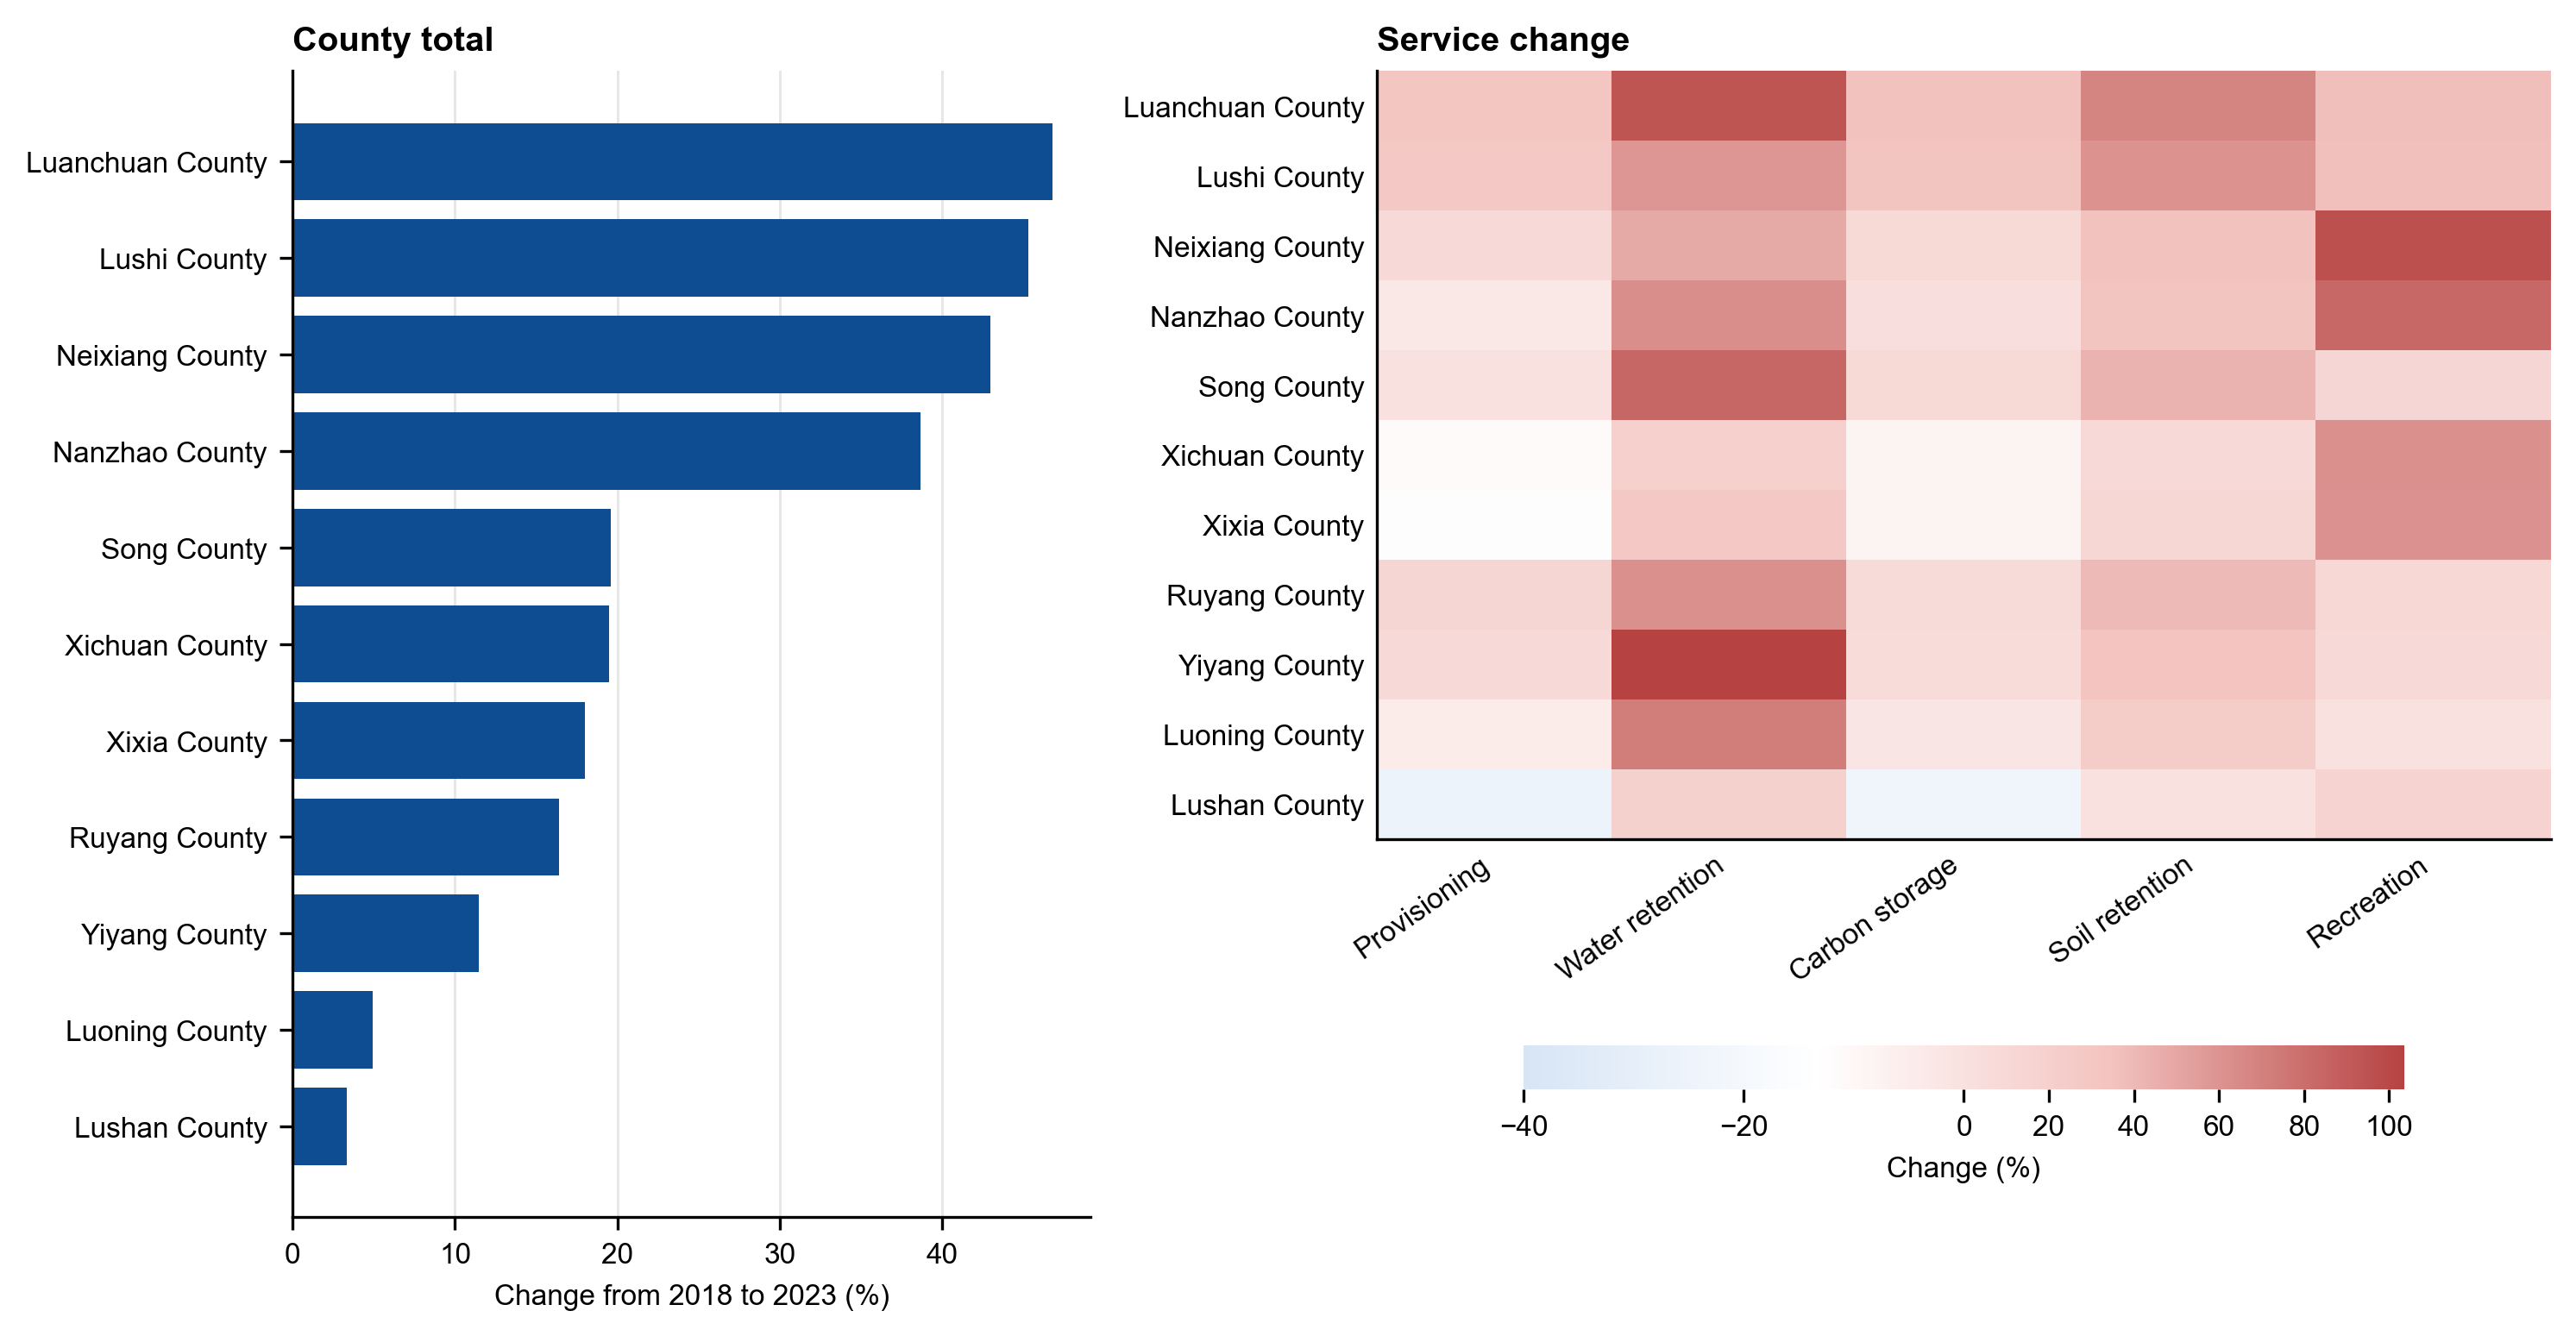

In [3]:
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np

from src.visualization import PALETTE, apply_style

apply_style()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5.2), gridspec_kw={'width_ratios': [0.85, 1.25]})

y = np.arange(len(counties))
ax1.barh(y, counties['change_pct'], color=PALETTE['navy'])
ax1.set_yticks(y, counties.index)
ax1.set_xlabel('Change from 2018 to 2023 (%)')
ax1.set_title('County total', loc='left', fontweight='bold')
ax1.grid(axis='x', color='#E6E6E6', linewidth=0.7)
ax1.set_axisbelow(True)

matrix = heat.to_numpy()
cmap = mcolors.LinearSegmentedColormap.from_list('change', ['#D7E5F5', '#FFFFFF', '#F3C4C0', '#B64342'])
norm = mcolors.TwoSlopeNorm(vmin=min(-40, float(matrix.min())), vcenter=0, vmax=max(90, float(matrix.max())))
image = ax2.imshow(matrix, aspect='auto', cmap=cmap, norm=norm)
ax2.set_xticks(np.arange(matrix.shape[1]), heat.columns, rotation=35, ha='right')
ax2.set_yticks(np.arange(matrix.shape[0]), heat.index)
ax2.set_title('Service change', loc='left', fontweight='bold')
ax2.tick_params(length=0)
colorbar = fig.colorbar(image, ax=ax2, location='bottom', shrink=0.75, pad=0.18)
colorbar.set_label('Change (%)')
colorbar.outline.set_visible(False)

fig.tight_layout()
output_base = ROOT / 'outputs' / 'charts' / 'county_comparison'
fig.savefig(output_base.with_suffix('.png'), dpi=300, bbox_inches='tight', facecolor='white')
fig.savefig(output_base.with_suffix('.svg'), bbox_inches='tight', facecolor='white')
plt.close(fig)

from IPython.display import Image, display
display(Image(filename=str(output_base.with_suffix('.png'))))


Luanchuan, Lushi, and Neixiang record the largest total increases. Lushan records the smallest aggregate increase, while some of its individual services decline.